# 01. Khám phá Dữ liệu & Kiểm toán Chất lượng (EDA)
**Đề tài:** Dự đoán khả năng khách hàng hủy đặt phòng khách sạn (*Hotel Booking Demand*)  
**Nguồn dữ liệu:** Antonio, Almeida, & Nunes (2019) — `data/raw/hotel_bookings.csv`

## Mục tiêu của Notebook
1. Kiểm toán toàn diện chất lượng dữ liệu thô: kích thước, kiểu dữ liệu, giá trị thiếu, bản ghi trùng lặp và các giá trị bất thường nghiệp vụ.
2. Xác minh trực tiếp các cột gây **rò rỉ nhãn (Data Leakage)**: `reservation_status` và `reservation_status_date`.
3. Khám phá phân phối biến mục tiêu `is_canceled`, tính mùa vụ theo thời gian (07/2015 – 08/2017) và mối quan hệ với các đặc trưng số & phân loại trọng yếu.
4. Xuất bộ 6 biểu đồ độ phân giải cao (`300 DPI`) vào thư mục `eda_figures/` phục vụ báo cáo học thuật.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Global plotting style (academic report quality, full Vietnamese glyph support via DejaVu Sans)
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
sns.set_palette("Set2")

RAW_PATH = Path("../data/raw/hotel_bookings.csv")
FIG_DIR = Path("../eda_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RAW_PATH)
print(f"Kích thước dữ liệu gốc: {df.shape[0]:,} dòng x {df.shape[1]} cột")
display(df.head(5))

Kích thước dữ liệu gốc: 119,390 dòng x 32 cột


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 1. Kiểm toán chất lượng dữ liệu (Data Quality Audit)
Ta kiểm tra đồng thời:
- Kiểu dữ liệu và tỷ lệ giá trị thiếu (`Missing Values`).
- Các bản ghi trùng lặp (`Duplicates`) trước và sau khi loại bỏ cột leakage.
- Các bản ghi vi phạm logic nghiệp vụ (`0` khách, `0` đêm, `adr < 0`, ngoại lai `adr`).
- Xác minh 100% rò rỉ nhãn của cột `reservation_status`.

In [2]:
# 1.1 Missing values audit
missing_df = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(3),
    "dtype": df.dtypes.astype(str),
    "nunique": df.nunique(dropna=False),
})
print("=== Bảng các cột có giá trị thiếu ===")
display(missing_df[missing_df["missing_count"] > 0].sort_values("missing_count", ascending=False))

# 1.2 Anomalies & Duplicates audit
zero_guests = ((df["adults"] + df["children"].fillna(0) + df["babies"]) == 0).sum()
zero_nights = ((df["stays_in_weekend_nights"] + df["stays_in_week_nights"]) == 0).sum()
neg_adr = (df["adr"] < 0).sum()
extreme_adr = (df["adr"] > 1000).sum()
dup_raw = df.duplicated().sum()

df_no_leak = df.drop(columns=["reservation_status", "reservation_status_date"])
dup_no_leak = df_no_leak.duplicated().sum()
df_dedup = df_no_leak.drop_duplicates()

audit_summary = pd.DataFrame([
    {"Hạng mục kiểm toán": "Tổng số bản ghi thô", "Số lượng": len(df), "Tỷ lệ (%)": 100.0},
    {"Hạng mục kiểm toán": "Dòng trùng lặp hoàn toàn (bảng gốc)", "Số lượng": dup_raw, "Tỷ lệ (%)": round(dup_raw / len(df) * 100, 2)},
    {"Hạng mục kiểm toán": "Dòng trùng lặp (sau bỏ reservation_status*)", "Số lượng": dup_no_leak, "Tỷ lệ (%)": round(dup_no_leak / len(df) * 100, 2)},
    {"Hạng mục kiểm toán": "Bản ghi còn lại sau khử trùng lặp", "Số lượng": len(df_dedup), "Tỷ lệ (%)": round(len(df_dedup) / len(df) * 100, 2)},
    {"Hạng mục kiểm toán": "Tổng số khách = 0 (bất hợp lệ)", "Số lượng": zero_guests, "Tỷ lệ (%)": round(zero_guests / len(df) * 100, 3)},
    {"Hạng mục kiểm toán": "Tổng số đêm = 0 (day-use)", "Số lượng": zero_nights, "Tỷ lệ (%)": round(zero_nights / len(df) * 100, 3)},
    {"Hạng mục kiểm toán": "Giá phòng ADR < 0 (lỗi nhập liệu)", "Số lượng": neg_adr, "Tỷ lệ (%)": round(neg_adr / len(df) * 100, 4)},
    {"Hạng mục kiểm toán": "Giá phòng ADR > 1000 (ngoại lai cực đại)", "Số lượng": extreme_adr, "Tỷ lệ (%)": round(extreme_adr / len(df) * 100, 4)},
])
print("\n=== Tóm tắt Kiểm toán Dữ liệu ===")
display(audit_summary)

# 1.3 Direct Leakage verification
print("\n=== Kiểm chứng Data Leakage: reservation_status vs is_canceled ===")
display(pd.crosstab(df["reservation_status"], df["is_canceled"], margins=True))

=== Bảng các cột có giá trị thiếu ===

=== Tóm tắt Kiểm toán Dữ liệu ===

=== Kiểm chứng Data Leakage: reservation_status vs is_canceled ===


,missing_count,missing_pct,dtype,nunique
company,112593,94.307,float64,353
agent,16340,13.686,float64,334
country,488,0.409,str,178
children,4,0.003,float64,6


,Hạng mục kiểm toán,Số lượng,Tỷ lệ (%)
0,Tổng số bản ghi thô,119390,100.0000
1,Dòng trùng lặp hoàn toàn (bảng gốc),31994,26.8000
2,Dòng trùng lặp (sau bỏ reservation_status*),32252,27.0100
3,Bản ghi còn lại sau khử trùng lặp,87138,72.9900
4,Tổng số khách = 0 (bất hợp lệ),180,0.1510
5,Tổng số đêm = 0 (day-use),715,0.5990
6,Giá phòng ADR < 0 (lỗi nhập liệu),1,0.0008
7,Giá phòng ADR > 1000 (ngoại lai cực đại),1,0.0008


is_canceled,0,1,All
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
All,75166,44224,119390


**Nhận xét kiểm toán quan trọng:**
1. **`reservation_status` rò rỉ nhãn 100%**: Mọi dòng có `Check-Out` đều có `is_canceled = 0`, mọi dòng `Canceled` hoặc `No-Show` đều có `is_canceled = 1`. Do đó, `reservation_status` và `reservation_status_date` **bắt buộc phải loại bỏ**.
2. **Tác động lớn của dòng trùng lặp**: Có tới `32.252` dòng trùng hoàn toàn (27,01%) sau khi bỏ 2 cột leakage. Nếu không khử trùng lặp trước khi chia Train/Test, bản ghi giống hệt nhau sẽ xuất hiện ở cả hai tập gây ảo giác hiệu năng (data leakage). Hơn nữa, tỷ lệ hủy giảm mạnh từ **37,04%** xuống **27,28%** sau khi khử trùng lặp, cho thấy các bản ghi trùng lặp tập trung chủ yếu ở các đơn đặt phòng bị hủy hàng loạt (theo đoàn/đại lý).
3. **Dữ liệu thiếu**: `company` thiếu 94,31% và `agent` thiếu 13,69% — đây không hẳn là lỗi mất dữ liệu ngẫu nhiên mà mang ý nghĩa nghiệp vụ *"khách đặt trực tiếp, không qua công ty/đại lý"*.

## 2. Phân phối Biến mục tiêu (`is_canceled`), Loại khách sạn & Chất lượng dữ liệu

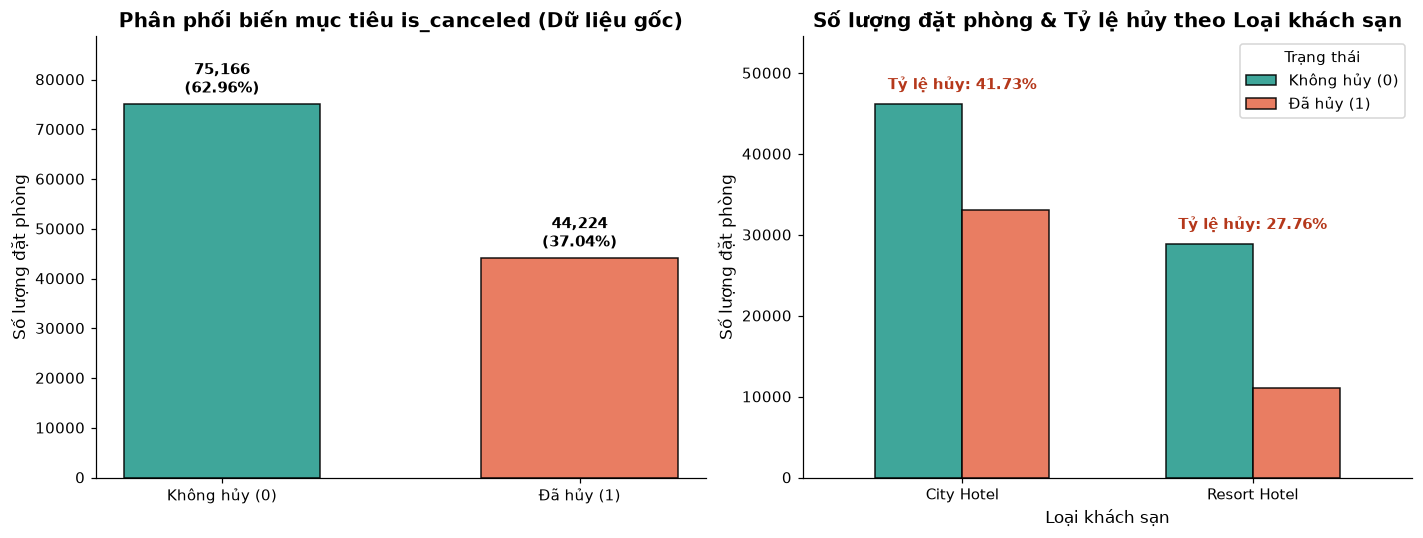

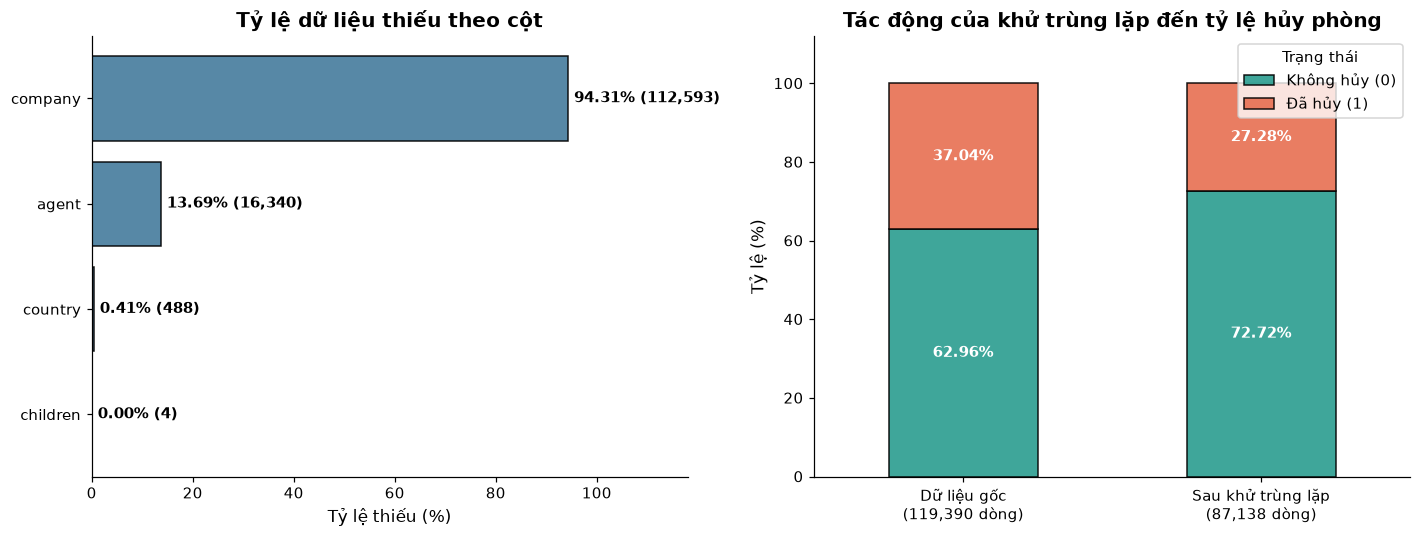

In [3]:
# Figure 01: Target distribution & Hotel comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel A: Overall target distribution
target_counts = df["is_canceled"].value_counts().sort_index()
target_pcts = df["is_canceled"].value_counts(normalize=True).sort_index() * 100
colors_target = ["#2a9d8f", "#e76f51"]
bars = axes[0].bar(["Không hủy (0)", "Đã hủy (1)"], target_counts.values, color=colors_target, width=0.55, edgecolor="black", alpha=0.9)
for bar, count, pct in zip(bars, target_counts.values, target_pcts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, count + 1200, f"{count:,}\n({pct:.2f}%)", ha="center", va="bottom", fontweight="bold", fontsize=10)
axes[0].set_title("Phân phối biến mục tiêu is_canceled (Dữ liệu gốc)")
axes[0].set_ylabel("Số lượng đặt phòng")
axes[0].set_ylim(0, target_counts.max() * 1.18)

# Panel B: Hotel type vs cancellation rate
hotel_stats = df.groupby("hotel")["is_canceled"].agg(["count", "mean"]).reset_index()
hotel_stats["cancel_pct"] = hotel_stats["mean"] * 100
hotel_counts = df.groupby(["hotel", "is_canceled"]).size().unstack(fill_value=0)
hotel_counts.plot(kind="bar", ax=axes[1], color=colors_target, edgecolor="black", alpha=0.9, width=0.6)
axes[1].set_title("Số lượng đặt phòng & Tỷ lệ hủy theo Loại khách sạn")
axes[1].set_xlabel("Loại khách sạn")
axes[1].set_ylabel("Số lượng đặt phòng")
axes[1].set_xticklabels(hotel_counts.index, rotation=0)
axes[1].legend(["Không hủy (0)", "Đã hủy (1)"], title="Trạng thái")

for idx, hotel in enumerate(hotel_counts.index):
    rate = hotel_stats.loc[hotel_stats["hotel"] == hotel, "cancel_pct"].values[0]
    ymax = hotel_counts.loc[hotel].max()
    axes[1].text(idx, ymax + 1800, f"Tỷ lệ hủy: {rate:.2f}%", ha="center", fontweight="bold", color="#b5381b", fontsize=10)
axes[1].set_ylim(0, hotel_counts.values.max() * 1.18)

plt.tight_layout()
plt.savefig(FIG_DIR / "01_target_and_hotel_distribution.png", bbox_inches="tight")
plt.show()

# Figure 02: Missing values & Deduplication impact
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

miss_plot = missing_df[missing_df["missing_count"] > 0].sort_values("missing_pct", ascending=True)
bars_m = axes[0].barh(miss_plot.index, miss_plot["missing_pct"], color="#457b9d", edgecolor="black", alpha=0.9)
for bar, (col, row) in zip(bars_m, miss_plot.iterrows()):
    axes[0].text(row["missing_pct"] + 1.2, bar.get_y() + bar.get_height() / 2,
                 f"{row['missing_pct']:.2f}% ({int(row['missing_count']):,})", va="center", fontsize=9.5, fontweight="bold")
axes[0].set_title("Tỷ lệ dữ liệu thiếu theo cột")
axes[0].set_xlabel("Tỷ lệ thiếu (%)")
axes[0].set_xlim(0, 118)

# Deduplication impact on target balance
comp_df = pd.DataFrame({
    "Dữ liệu gốc\n(119,390 dòng)": [62.96, 37.04],
    "Sau khử trùng lặp\n(87,138 dòng)": [
        (df_dedup["is_canceled"] == 0).mean() * 100,
        (df_dedup["is_canceled"] == 1).mean() * 100,
    ],
}, index=["Không hủy (0)", "Đã hủy (1)"]).T

comp_df.plot(kind="bar", stacked=True, ax=axes[1], color=colors_target, edgecolor="black", alpha=0.9, width=0.5)
for idx, (label, row) in enumerate(comp_df.iterrows()):
    axes[1].text(idx, row["Không hủy (0)"] / 2, f"{row['Không hủy (0)']:.2f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=10)
    axes[1].text(idx, row["Không hủy (0)"] + row["Đã hủy (1)"] / 2, f"{row['Đã hủy (1)']:.2f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=10)
axes[1].set_title("Tác động của khử trùng lặp đến tỷ lệ hủy phòng")
axes[1].set_ylabel("Tỷ lệ (%)")
axes[1].set_xticklabels(comp_df.index, rotation=0)
axes[1].legend(title="Trạng thái", loc="upper right")
axes[1].set_ylim(0, 112)

plt.tight_layout()
plt.savefig(FIG_DIR / "02_missing_and_duplicates_audit.png", bbox_inches="tight")
plt.show()

## 3. Phân tích Mùa vụ & Diễn biến theo Thời gian (2015 – 2017)
Dữ liệu trải dài 26 tháng liên tiếp (từ tháng 7/2015 đến tháng 8/2017). Ta khảo sát sản lượng đặt phòng và tỷ lệ hủy theo từng tháng (tách theo loại khách sạn) và theo từng năm nhằm làm cơ sở cho phép kiểm thử Out-of-Time (OOT).

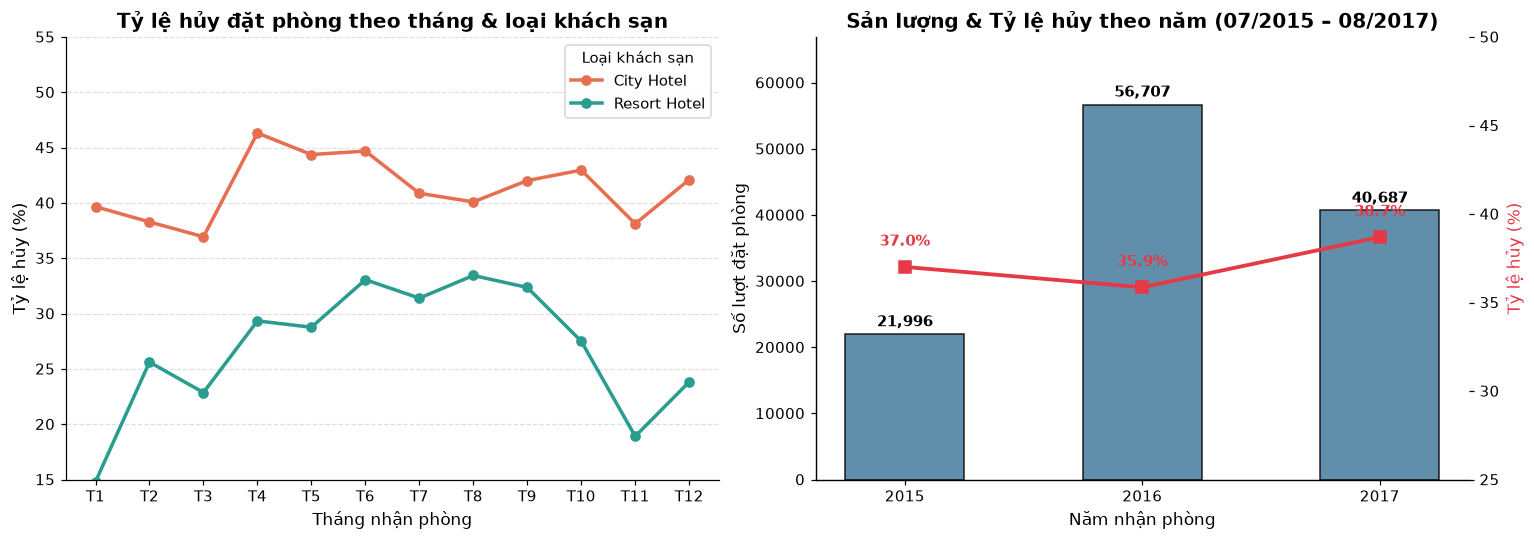

In [4]:
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]
month_short = ["T1", "T2", "T3", "T4", "T5", "T6", "T7", "T8", "T9", "T10", "T11", "T12"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel A: Monthly booking volume & cancellation rate by hotel
monthly = df.groupby(["arrival_date_month", "hotel"])["is_canceled"].agg(["count", "mean"]).reset_index()
monthly["arrival_date_month"] = pd.Categorical(monthly["arrival_date_month"], categories=month_order, ordered=True)
monthly = monthly.sort_values("arrival_date_month")

for hotel, color in [("City Hotel", "#e76f51"), ("Resort Hotel", "#2a9d8f")]:
    sub = monthly[monthly["hotel"] == hotel]
    axes[0].plot(range(12), sub["mean"] * 100, marker="o", linewidth=2.3, label=hotel, color=color)

axes[0].set_xticks(range(12))
axes[0].set_xticklabels(month_short)
axes[0].set_title("Tỷ lệ hủy đặt phòng theo tháng & loại khách sạn")
axes[0].set_xlabel("Tháng nhận phòng")
axes[0].set_ylabel("Tỷ lệ hủy (%)")
axes[0].set_ylim(15, 55)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
axes[0].legend(title="Loại khách sạn")

# Panel B: Yearly volume & cancellation rate (also showing OOT boundary context)
yearly = df.groupby("arrival_date_year")["is_canceled"].agg(["count", "mean"]).reset_index()
bars_y = axes[1].bar(yearly["arrival_date_year"].astype(str), yearly["count"], color="#457b9d", width=0.5, edgecolor="black", alpha=0.85, label="Tổng lượt đặt")
ax2 = axes[1].twinx()
ax2.plot(yearly["arrival_date_year"].astype(str), yearly["mean"] * 100, color="#e63946", marker="s", linewidth=2.5, markersize=8, label="Tỷ lệ hủy (%)")
ax2.spines["top"].set_visible(False)

for idx, row in yearly.iterrows():
    axes[1].text(idx, row["count"] + 1200, f"{int(row['count']):,}", ha="center", fontweight="bold", fontsize=9.5)
    ax2.text(idx, row["mean"] * 100 + 1.2, f"{row['mean']*100:.1f}%", ha="center", color="#e63946", fontweight="bold", fontsize=9.5)

axes[1].set_title("Sản lượng & Tỷ lệ hủy theo năm (07/2015 – 08/2017)")
axes[1].set_xlabel("Năm nhận phòng")
axes[1].set_ylabel("Số lượt đặt phòng")
axes[1].set_ylim(0, yearly["count"].max() * 1.18)
ax2.set_ylabel("Tỷ lệ hủy (%)", color="#e63946")
ax2.set_ylim(25, 50)

plt.tight_layout()
plt.savefig(FIG_DIR / "03_seasonality_monthly_cancellation.png", bbox_inches="tight")
plt.show()

## 4. Phân tích các Biến số Trọng yếu theo Nhãn `is_canceled`
Khảo sát sự khác biệt phân phối giữa nhóm **Không hủy (0)** và **Đã hủy (1)** trên 4 biến số có ý nghĩa thực tiễn cao: `lead_time` (số ngày đặt trước), `adr` (giá phòng trung bình/đêm), `total_nights` (tổng số đêm lưu trú) và `total_of_special_requests` (số yêu cầu đặc biệt).

=== Thống kê trung bình & trung vị theo trạng thái hủy ===


lead_time         ... total_of_special_requests       
                 mean median  ...                      mean median
is_canceled                   ...                                 
0               79.98   45.0  ...                      0.71    1.0
1              144.85  113.0  ...                      0.33    0.0

[2 rows x 12 columns]

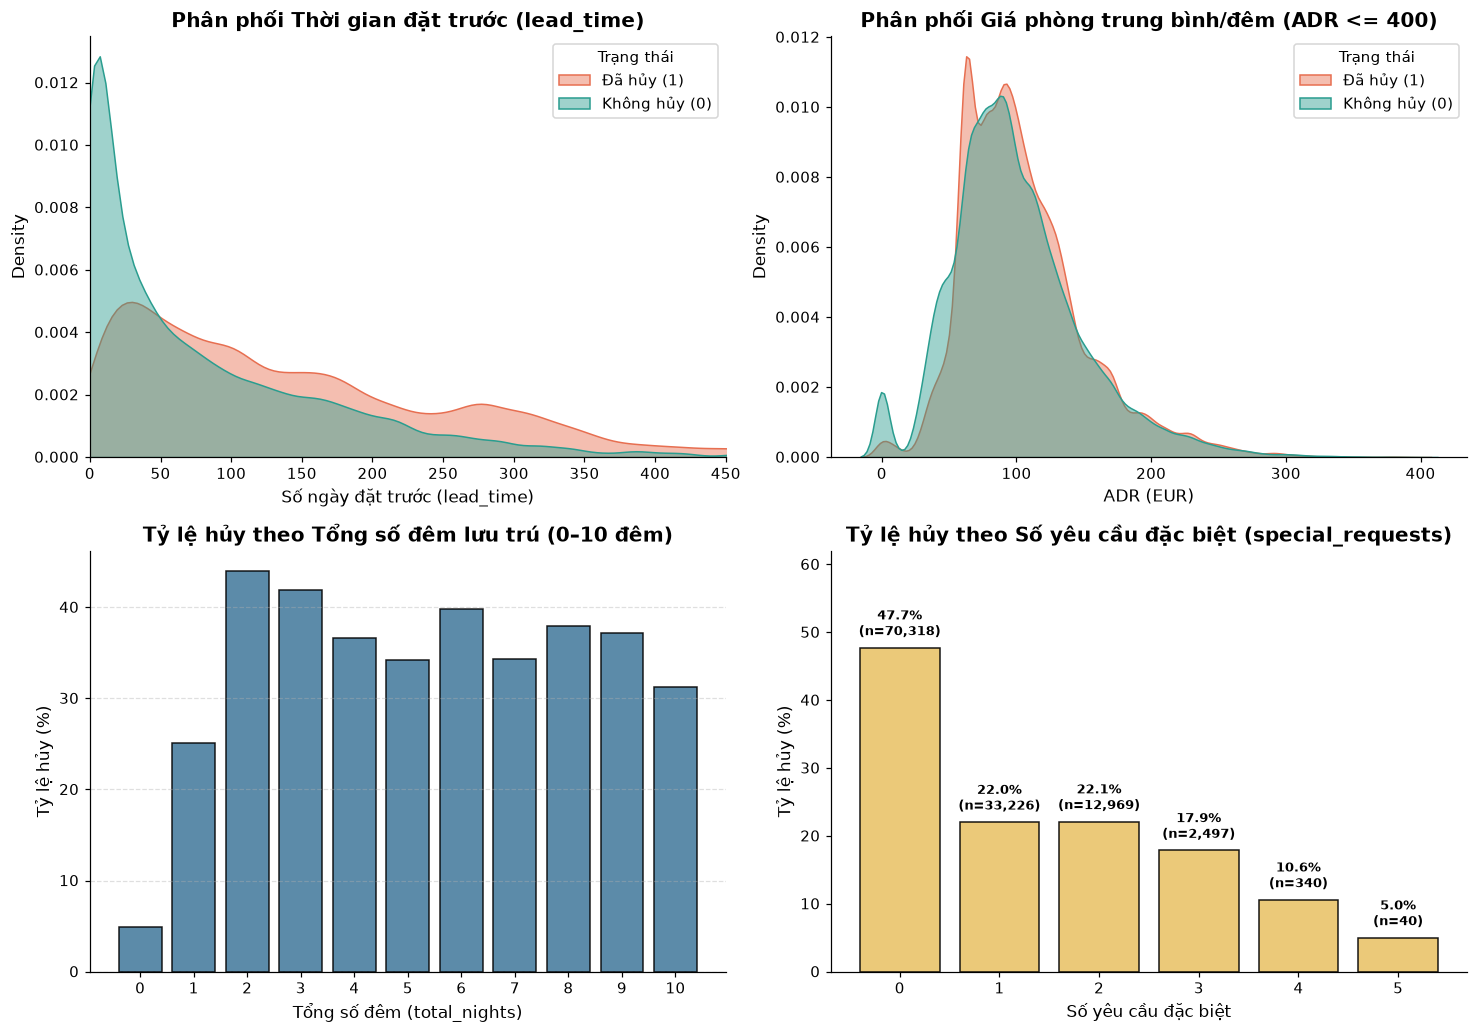

In [5]:
df_eda = df.copy()
df_eda["total_nights"] = df_eda["stays_in_weekend_nights"] + df_eda["stays_in_week_nights"]

num_check = ["lead_time", "adr", "total_nights", "booking_changes", "previous_cancellations", "total_of_special_requests"]
print("=== Thống kê trung bình & trung vị theo trạng thái hủy ===")
display(df_eda.groupby("is_canceled")[num_check].agg(["mean", "median"]).round(2))

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.5))

# 1. Lead time KDE
sns.kdeplot(data=df_eda, x="lead_time", hue="is_canceled", fill=True, common_norm=False,
            palette=["#2a9d8f", "#e76f51"], alpha=0.45, ax=axes[0, 0])
axes[0, 0].set_title("Phân phối Thời gian đặt trước (lead_time)")
axes[0, 0].set_xlabel("Số ngày đặt trước (lead_time)")
axes[0, 0].set_xlim(0, 450)
axes[0, 0].legend(["Đã hủy (1)", "Không hủy (0)"], title="Trạng thái")

# 2. ADR boxplot / KDE (clipped at 400 for visual clarity)
adr_clean = df_eda[(df_eda["adr"] >= 0) & (df_eda["adr"] <= 400)]
sns.kdeplot(data=adr_clean, x="adr", hue="is_canceled", fill=True, common_norm=False,
            palette=["#2a9d8f", "#e76f51"], alpha=0.45, ax=axes[0, 1])
axes[0, 1].set_title("Phân phối Giá phòng trung bình/đêm (ADR <= 400)")
axes[0, 1].set_xlabel("ADR (EUR)")
axes[0, 1].legend(["Đã hủy (1)", "Không hủy (0)"], title="Trạng thái")

# 3. Total nights cancellation rate (0..10 nights)
nights_sub = df_eda[df_eda["total_nights"] <= 10]
nights_rate = nights_sub.groupby("total_nights")["is_canceled"].mean() * 100
axes[1, 0].bar(nights_rate.index, nights_rate.values, color="#457b9d", edgecolor="black", alpha=0.88)
axes[1, 0].set_title("Tỷ lệ hủy theo Tổng số đêm lưu trú (0–10 đêm)")
axes[1, 0].set_xlabel("Tổng số đêm (total_nights)")
axes[1, 0].set_ylabel("Tỷ lệ hủy (%)")
axes[1, 0].set_xticks(range(0, 11))
axes[1, 0].grid(axis="y", linestyle="--", alpha=0.4)

# 4. Special requests cancellation rate
req_stats = df_eda.groupby("total_of_special_requests")["is_canceled"].agg(["count", "mean"])
bars_r = axes[1, 1].bar(req_stats.index.astype(str), req_stats["mean"] * 100, color="#e9c46a", edgecolor="black", alpha=0.9)
for bar, (_, row) in zip(bars_r, req_stats.iterrows()):
    axes[1, 1].text(bar.get_x() + bar.get_width() / 2, row["mean"] * 100 + 1.2,
                    f"{row['mean']*100:.1f}%\n(n={int(row['count']):,})", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
axes[1, 1].set_title("Tỷ lệ hủy theo Số yêu cầu đặc biệt (special_requests)")
axes[1, 1].set_xlabel("Số yêu cầu đặc biệt")
axes[1, 1].set_ylabel("Tỷ lệ hủy (%)")
axes[1, 1].set_ylim(0, 62)

plt.tight_layout()
plt.savefig(FIG_DIR / "04_numerical_distributions_by_target.png", bbox_inches="tight")
plt.show()

## 5. Phân tích các Biến phân loại Trọng yếu & Phát hiện Nghiệp vụ
Ta phân tích tỷ lệ hủy theo `deposit_type`, `market_segment`, `customer_type`, và đặc trưng kỹ thuật `room_type_changed` (`reserved_room_type != assigned_room_type`).

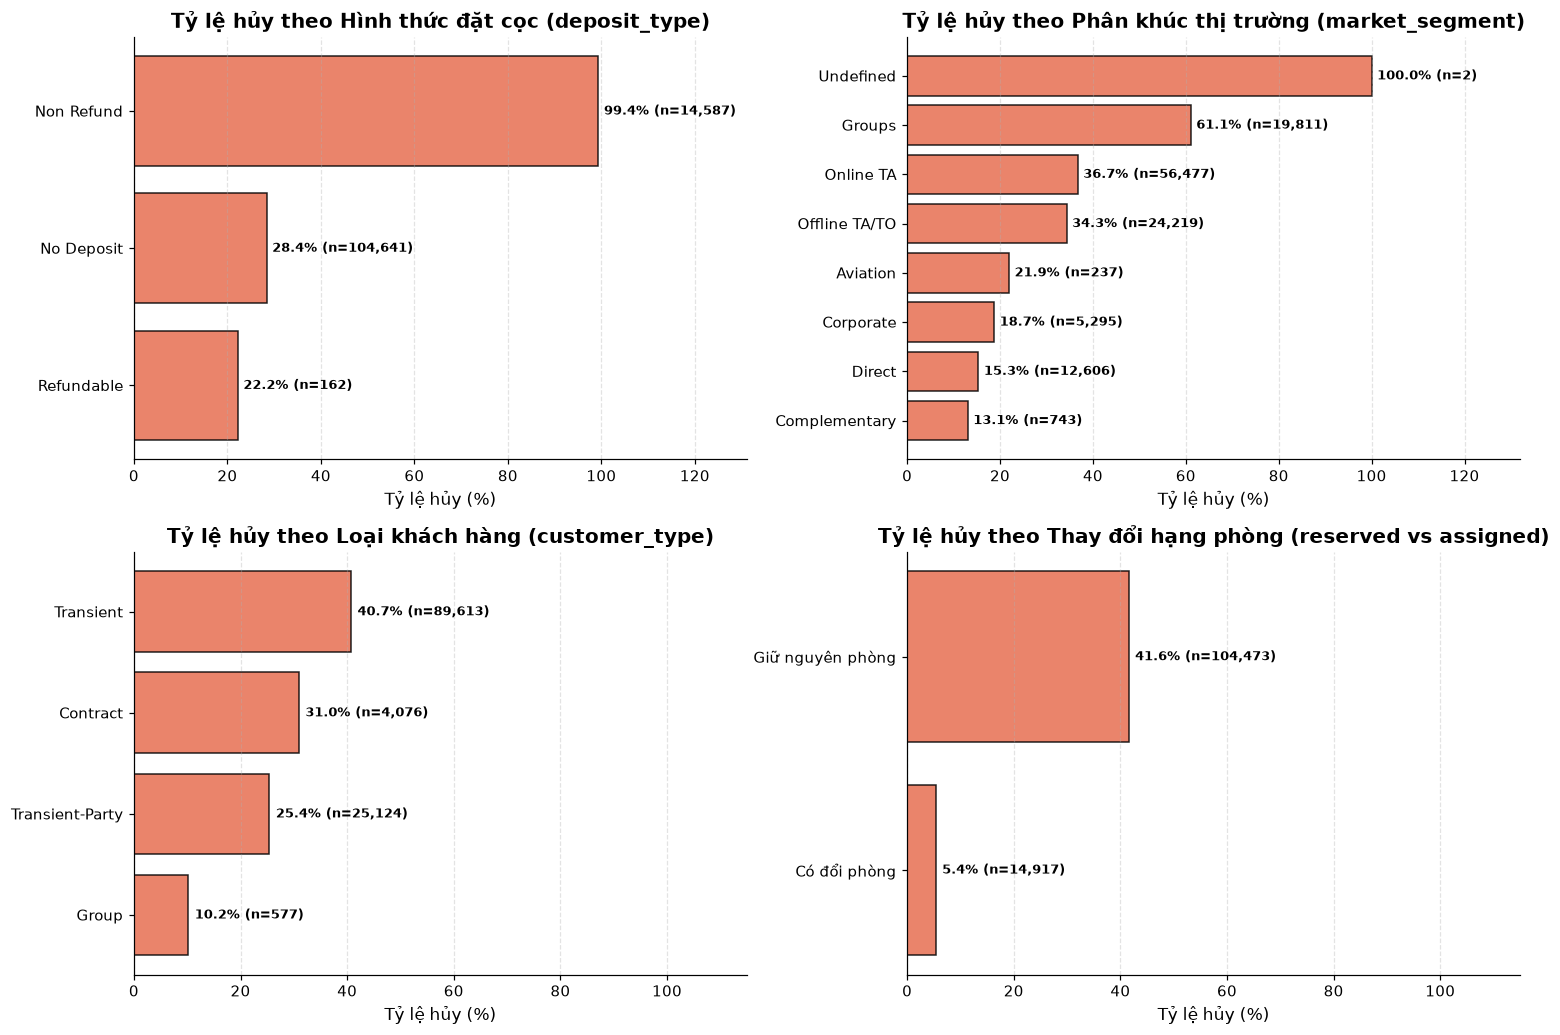

In [6]:
df_eda["room_type_changed"] = np.where(
    df_eda["reserved_room_type"] != df_eda["assigned_room_type"],
    "Có đổi phòng", "Giữ nguyên phòng"
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

cat_panels = [
    ("deposit_type", "Tỷ lệ hủy theo Hình thức đặt cọc (deposit_type)", axes[0, 0]),
    ("market_segment", "Tỷ lệ hủy theo Phân khúc thị trường (market_segment)", axes[0, 1]),
    ("customer_type", "Tỷ lệ hủy theo Loại khách hàng (customer_type)", axes[1, 0]),
    ("room_type_changed", "Tỷ lệ hủy theo Thay đổi hạng phòng (reserved vs assigned)", axes[1, 1]),
]

for col, title, ax in cat_panels:
    stats = df_eda.groupby(col)["is_canceled"].agg(["count", "mean"]).sort_values("mean", ascending=True)
    stats["pct"] = stats["mean"] * 100
    bars = ax.barh(stats.index.astype(str), stats["pct"], color="#e76f51", edgecolor="black", alpha=0.85)
    for bar, (_, row) in zip(bars, stats.iterrows()):
        ax.text(row["pct"] + 1.2, bar.get_y() + bar.get_height() / 2,
                f"{row['pct']:.1f}% (n={int(row['count']):,})", va="center", fontsize=8.8, fontweight="bold")
    ax.set_title(title)
    ax.set_xlabel("Tỷ lệ hủy (%)")
    ax.set_xlim(0, max(stats["pct"].max() * 1.32, 115))
    ax.grid(axis="x", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.savefig(FIG_DIR / "05_categorical_cancellation_rates.png", bbox_inches="tight")
plt.show()

### Ghi chú chuyên sâu về 2 hiện tượng đặc thù của bộ dữ liệu:
1. **`deposit_type = Non Refund` có tỷ lệ hủy 99,36% (`14.587` đơn)**: Về trực giác thông thường, đặt cọc không hoàn lại đáng lẽ ít bị hủy. Tuy nhiên theo nghiên cứu gốc (Antonio et al., 2019), tại các khách sạn Bồ Đào Nha này, nhiều đơn đặt phòng theo đoàn/OTA có rủi ro cao bị yêu cầu thanh toán trước (`Non Refund`), và khi đến hạn không thanh toán thành công, hệ thống PMS tự động hủy đơn hàng loạt.
2. **`room_type_changed` (`reserved_room_type != assigned_room_type`)**: Các đơn bị/được đổi hạng phòng có tỷ lệ hủy rất thấp (~5,4%) so với nhóm giữ nguyên (~41,6%), bởi việc nâng hạng/điều phối lại phòng thường chỉ diễn ra sát thời điểm nhận phòng khi khách chắc chắn đến. Trong phạm vi đề tài chuẩn học thuật này, ta giữ lại các cột trên theo chuẩn Kaggle benchmark và ghi nhận rõ hạn chế này khi diễn giải kết quả ở Notebook 04.

## 6. Ma trận tương quan (Spearman Correlation Heatmap)

Top biến số có tương quan Spearman mạnh nhất với is_canceled:


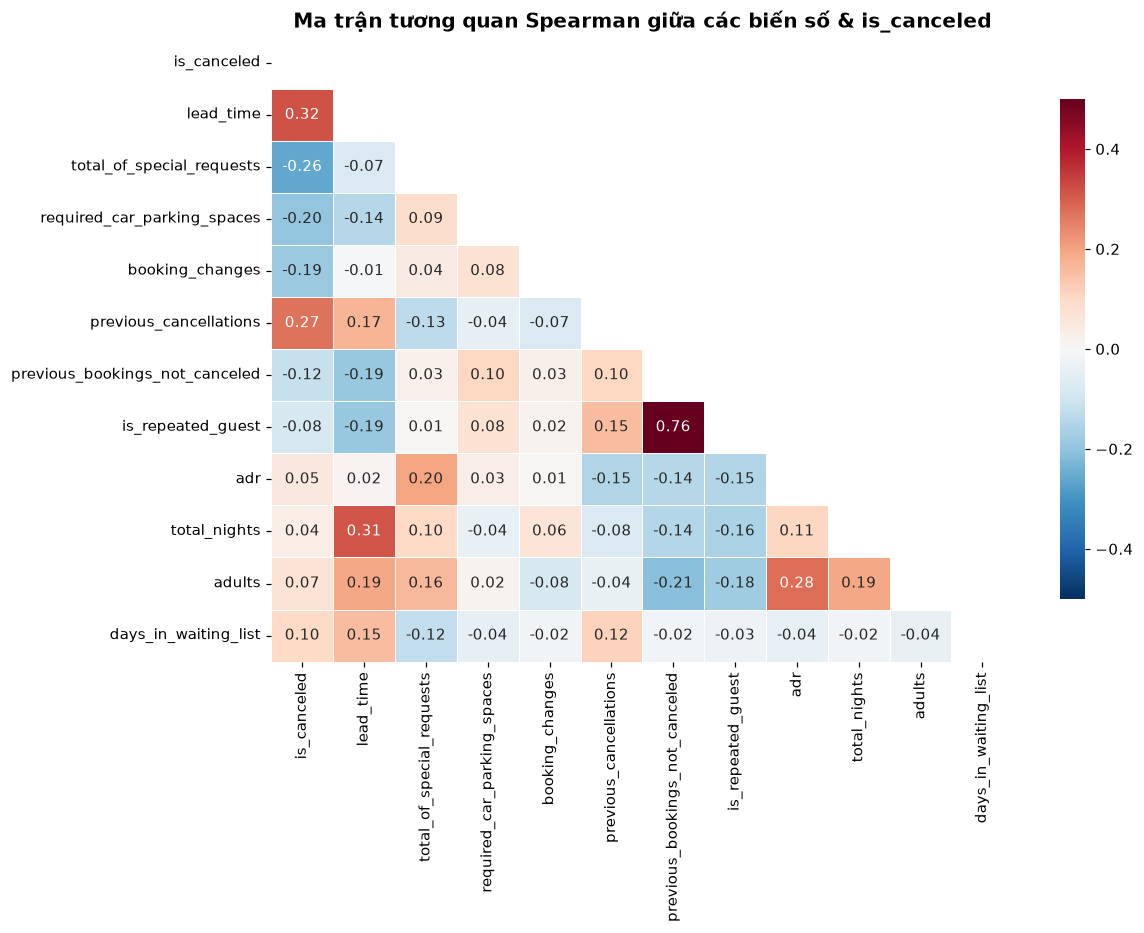

,spearman_corr
lead_time,0.3166
previous_cancellations,0.2702
total_of_special_requests,-0.2585
required_car_parking_spaces,-0.1974
booking_changes,-0.1851
previous_bookings_not_canceled,-0.1154
days_in_waiting_list,0.0982
is_repeated_guest,-0.0848
adults,0.0670
adr,0.0509


In [7]:
num_cols_corr = [
    "is_canceled", "lead_time", "total_of_special_requests", "required_car_parking_spaces",
    "booking_changes", "previous_cancellations", "previous_bookings_not_canceled",
    "is_repeated_guest", "adr", "total_nights", "adults", "days_in_waiting_list",
]
corr_mat = df_eda[num_cols_corr].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 8.5))
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(
    corr_mat, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
    center=0, vmin=-0.5, vmax=0.5, linewidths=0.5, ax=ax, cbar_kws={"shrink": 0.8}
)
ax.set_title("Ma trận tương quan Spearman giữa các biến số & is_canceled")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_correlation_heatmap.png", bbox_inches="tight")
plt.show()

print("Top biến số có tương quan Spearman mạnh nhất với is_canceled:")
display(corr_mat["is_canceled"].drop("is_canceled").sort_values(key=abs, ascending=False).to_frame("spearman_corr").round(4))

## 7. Tổng kết phát hiện chính từ EDA (Định hướng cho Notebook 02)
- **Loại bỏ rò rỉ nhãn trực tiếp**: Drop `reservation_status` và `reservation_status_date`.
- **Xử lý trùng lặp bắt buộc**: Khử `32.252` dòng trùng lặp trước khi chia Train/Test để triệt tiêu rò rỉ mẫu giống hệt nhau giữa hai tập (tỷ lệ nhãn dương thực tế sau khử trùng là `27,28%`).
- **Làm sạch bất thường**: Loại `180` dòng có `0` khách, `1` dòng `adr < 0`, `1` dòng ngoại lai cực đại `adr = 5400`.
- **Tạo đặc trưng giàu tín hiệu (Feature Engineering)**: `total_nights`, `total_guests`, `room_type_changed`, `prev_cancel_ratio`, `adr_per_person`, `estimated_total_revenue`, `has_agent`, `has_company`, `arrival_month_sin/cos`.
- **Mã hóa biến nhiều giá trị**: `country` (178), `agent` (333), `company` (352) có cardinality lớn $ightarrow$ sử dụng `TargetEncoder` khớp trong từng fold CV ở Notebook 03 thay vì One-Hot toàn bộ.